# Authoring CARLA bus stops

Bus stops are an **input** to the map layer, not something derived from it.
In a real deployment you would say where the stops are rather than let a
program guess — so they are hand-authored, version-controlled, and stored one
file per town under `src/map/carla_maps/`.

This notebook is the aid for producing that file. It proposes a well-spread
set of legal stop sites, shows them to you on a plan view and in the CARLA
world itself, and writes the result out. Nothing here runs in production:
`CarlaMapProvider` only ever *reads* the file this produces.

## What makes a site legal

A bus stop needs somewhere a bus can actually stop:

- on a **Driving** lane, so the bus can reach it;
- **not inside a junction**, and clear of both ends of its road segment, so a
  stopped bus does not block an intersection;
- with a **Shoulder immediately to the right**, which is CARLA's way of
  saying there is room to pull over;
- on a segment long enough to be worth stopping in.

!!! note "The junction test belongs on the stop, not the segment"
    An early version of this rejected any topology segment whose *endpoints*
    were in a junction. In CARLA that is almost every segment — they run
    junction to junction, so their endpoints are junction waypoints by
    construction. It discarded 144 of Town01's 160 segments and left only the
    four perimeter roads. The test has to be on the candidate position.

## How a stop is addressed

By its OpenDRIVE identity — `road_id`, `lane_id`, `s` — which
`Map.get_waypoint_xodr` resolves back to the exact waypoint. Measured on
Town01 that round-trips to within **0.0006 m**, so the file survives server
restarts and map reloads.

The world coordinates are cached alongside for plotting and review, and a
mismatch on load is a useful warning that the file was written against a
different version of the town.

`lane_id`'s sign carries the driving direction, so a stop inherently serves
**one direction** of its road. That matches the rest of the project, where
`TransitGraph` nodes are directed road edges.

## Configuration

In [1]:
# =========================
# Which town
# =========================
TOWN = "Town01"

# =========================
# What counts as a legal site
# =========================
JUNCTION_CLEARANCE_M = 10.0   # keep this far from either end of a segment
MIN_SEGMENT_M = 24.0          # ignore segments shorter than this
STEP_M = 2.0                  # sampling resolution along a segment

# =========================
# How many stops, and how spread out
# =========================
WANTED_STOPS = 15
MAX_PER_ROAD_LANE = 2         # stops a single road-lane may host

# Long perimeter roads dominate a pure spread objective, so the cap is what
# pushes stops onto the interior streets.

# =========================
# Server
# =========================
CARLA_HOST = "localhost"
CARLA_PORT = 2000

In [2]:
import collections

import carla
import matplotlib.pyplot as plt
import networkx

from src.map.carla_stops import CarlaStop, load_stops, save_stops

client = carla.Client(CARLA_HOST, CARLA_PORT)
client.set_timeout(60.0)

world = client.get_world()
if TOWN not in world.get_map().name:
    world = client.load_world(TOWN)
carla_map = world.get_map()

print(f"connected to {carla_map.name}")
print(f"{len(carla_map.get_topology())} topology segments")

connected to Carla/Maps/Town01
160 topology segments


## Finding legal sites

`get_topology()` hands back one `(entry, exit)` waypoint pair per lane
segment. Walking from entry to exit gives the positions along it — but
`next()` forks at junction approaches, so the walk has to follow the branch
that stays on the same road and lane, or it wanders into a neighbour.

In [3]:
def walk_segment(entry, exit_wp):
    """
    Walk a topology segment, staying on its own road and lane.

    :param entry: Waypoint at the start of the segment.
    :param exit_wp: Waypoint at the end of the segment.
    :return: Waypoints from entry towards exit, STEP_M apart.
    """
    walked = [entry]
    current = entry
    for _ in range(400):
        forward = [w for w in current.next(STEP_M)
                   if w.road_id == entry.road_id
                   and w.lane_id == entry.lane_id]
        if not forward:
            break
        current = forward[0]
        walked.append(current)
        if current.transform.location.distance(
                exit_wp.transform.location) < STEP_M:
            break
    return walked


def has_pull_over(waypoint):
    """Return True when a shoulder sits immediately to the right."""
    right = waypoint.get_right_lane()
    return right is not None and right.lane_type == carla.LaneType.Shoulder


def legal_sites():
    """
    Return every waypoint where a bus could legally stop.
    :return: List of candidate waypoints.
    """
    sites = []
    for entry, exit_wp in carla_map.get_topology():
        walked = walk_segment(entry, exit_wp)
        if len(walked) < 2:
            continue
        cumulative = [0.0]
        for i in range(1, len(walked)):
            cumulative.append(
                cumulative[-1]
                + walked[i - 1].transform.location.distance(
                    walked[i].transform.location))
        length = cumulative[-1]
        if length < MIN_SEGMENT_M:
            continue
        for waypoint, travelled in zip(walked, cumulative):
            if travelled < JUNCTION_CLEARANCE_M:
                continue
            if travelled > length - JUNCTION_CLEARANCE_M:
                break
            if waypoint.is_junction or not has_pull_over(waypoint):
                continue
            sites.append(waypoint)
    return sites


sites = legal_sites()
road_lanes = {(w.road_id, w.lane_id) for w in sites}
print(f"{len(sites)} legal sites on {len(road_lanes)} distinct road-lanes")

3318 legal sites on 44 distinct road-lanes


## Choosing a spread

Farthest-point sampling: repeatedly take the site furthest from everything
already chosen. On its own it hugs the map's extremes, so `MAX_PER_ROAD_LANE`
caps how much of the set any one road can absorb.

In [4]:
def select(sites, wanted, cap):
    """
    Pick well-spread sites, capping how many share a road-lane.

    :param sites: Candidate waypoints.
    :param wanted: How many stops to choose.
    :param cap: Maximum stops permitted on one (road_id, lane_id).
    :return: The chosen waypoints.
    """
    used = collections.Counter()
    chosen = [max(sites, key=lambda w: w.transform.location.x)]
    used[(chosen[0].road_id, chosen[0].lane_id)] += 1

    while len(chosen) < wanted:
        best, best_distance = None, -1.0
        for waypoint in sites:
            if used[(waypoint.road_id, waypoint.lane_id)] >= cap:
                continue
            location = waypoint.transform.location
            nearest = min(location.distance(c.transform.location)
                          for c in chosen)
            if nearest > best_distance:
                best, best_distance = waypoint, nearest
        if best is None or best_distance <= 1.0:
            break
        chosen.append(best)
        used[(best.road_id, best.lane_id)] += 1
    return chosen


chosen = select(sites, WANTED_STOPS, MAX_PER_ROAD_LANE)

# South to north, west to east, so the IDs read in a sensible order.
chosen.sort(key=lambda w: (round(w.transform.location.y, -1),
                           w.transform.location.x))

stops = [
    CarlaStop(
        id=f"s{number:02d}",
        road_id=w.road_id,
        lane_id=w.lane_id,
        s=w.s,
        x=w.transform.location.x,
        y=w.transform.location.y,
        z=w.transform.location.z,
    )
    for number, w in enumerate(chosen, 1)
]

print(f"{'id':<5} {'road':>5} {'lane':>5} {'s':>8} {'x':>8} {'y':>8}")
for stop in stops:
    print(f"{stop.id:<5} {stop.road_id:5d} {stop.lane_id:5d} "
          f"{stop.s:8.2f} {stop.x:8.1f} {stop.y:8.1f}")

id     road  lane        s        x        y
s01       3    -1    10.00     69.4     -2.0
s02       1    -1    68.00    257.6     -2.0
s03       8    -1   296.00    396.4     22.5
s04      25     1    19.18    158.0     30.2
s05      22     1    29.69     92.4     97.8
s06      17    -1    36.00    334.8    105.0
s07       4    -1   122.00    223.4    133.5
s08      15    -1   134.00     -2.0    144.0
s09       8    -1   132.00    396.3    186.5
s10      12    -1    12.00    113.4    199.1
s11      12    -1   196.00    297.4    199.2
s12       8     1    38.69    392.3    279.9
s13      15    -1   296.00     -2.0    306.0
s14       6    -1    54.00    155.6    330.6
s15       6    -1   214.00    315.6    330.6


## Is the set any good?

In [5]:
graph = networkx.DiGraph()
for entry, exit_wp in carla_map.get_topology():
    start = (round(entry.transform.location.x, 1),
             round(entry.transform.location.y, 1))
    end = (round(exit_wp.transform.location.x, 1),
           round(exit_wp.transform.location.y, 1))
    if start != end:
        graph.add_edge(start, end,
                       length=entry.transform.location.distance(
                           exit_wp.transform.location))

largest = max(networkx.strongly_connected_components(graph), key=len)


def nearest_node(x, y):
    """Return the graph node closest to a point."""
    return min(graph.nodes(),
               key=lambda n: (n[0] - x) ** 2 + (n[1] - y) ** 2)


anchors = {s.id: nearest_node(s.x, s.y) for s in stops}
stranded = [sid for sid, node in anchors.items() if node not in largest]

legs = []
for source in stops:
    reach = networkx.single_source_dijkstra_path_length(
        graph, anchors[source.id], weight="length")
    legs += [reach[anchors[t.id]] for t in stops
             if t.id != source.id and anchors[t.id] in reach]
legs.sort()

roads = collections.Counter((s.road_id, s.lane_id) for s in stops)
spacing = sorted(((a.x - b.x) ** 2 + (a.y - b.y) ** 2) ** 0.5
                 for i, a in enumerate(stops) for b in stops[i + 1:])

print(f"stops                {len(stops)}")
print(f"distinct road-lanes  {len(roads)}")
print(f"straight-line gap    min {spacing[0]:.0f} m, "
      f"median {spacing[len(spacing) // 2]:.0f} m")
print(f"road-distance leg    median {legs[len(legs) // 2]:.0f} m "
      f"(~{legs[len(legs) // 2] / 6:.0f} s at 6 m/s)")
if stranded:
    print(f"UNREACHABLE STOPS: {stranded}")
else:
    print("reachability         every stop can reach every other")

stops                15
distinct road-lanes  11
straight-line gap    min 92 m, median 229 m
road-distance leg    median 555 m (~93 s at 6 m/s)
reachability         every stop can reach every other


Compare the median leg against the mock's campus map, where it is roughly
130 s. A CARLA town is far smaller in metres but slower to drive, so the two
land in the same range — which is what keeps the routing behaviour
comparable.

## Plan view

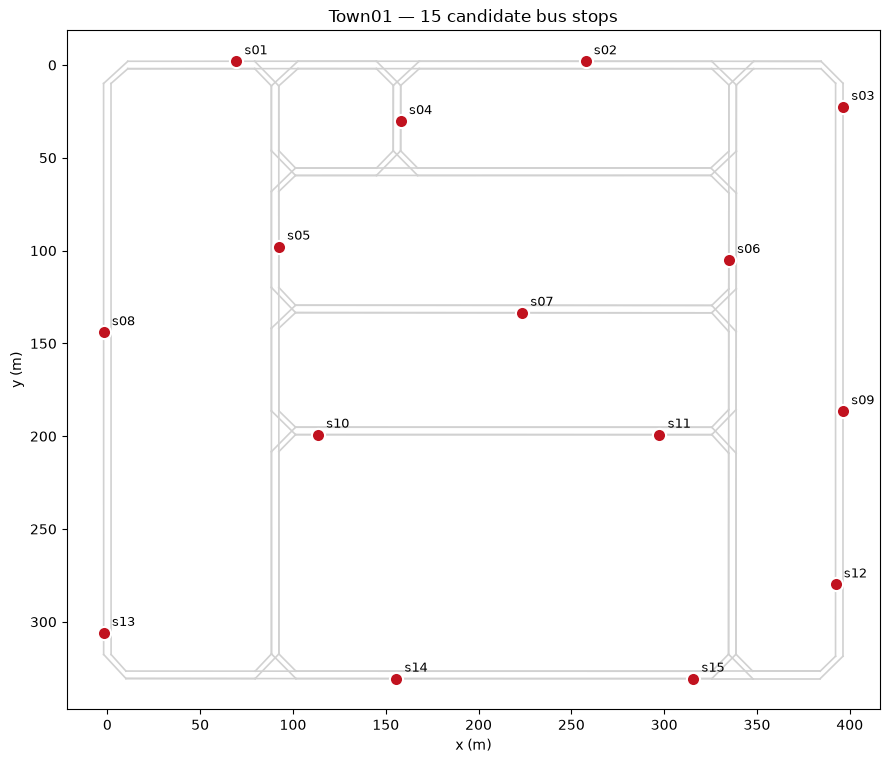

In [6]:
figure, axes = plt.subplots(figsize=(9, 9))
for entry, exit_wp in carla_map.get_topology():
    a, b = entry.transform.location, exit_wp.transform.location
    axes.plot([a.x, b.x], [a.y, b.y], color="0.82", linewidth=1.2, zorder=1)

axes.scatter([s.x for s in stops], [s.y for s in stops], s=90,
             color="#c1121f", zorder=3, edgecolor="white", linewidth=1.5)
for stop in stops:
    axes.annotate(stop.id, (stop.x, stop.y), fontsize=9,
                  xytext=(6, 5), textcoords="offset points", zorder=4)

axes.set_aspect("equal")
axes.invert_yaxis()          # CARLA's y grows southward
axes.set_title(f"{TOWN} — {len(stops)} candidate bus stops")
axes.set_xlabel("x (m)")
axes.set_ylabel("y (m)")
plt.tight_layout()
plt.show()

## See them in the world

Draws a marker and label at each stop, so they can be inspected from the
spectator camera. Purely visual — nothing is written by this cell.

In [7]:
MARKER_LIFETIME_S = 600.0

for stop in stops:
    world.debug.draw_point(
        carla.Location(x=stop.x, y=stop.y, z=stop.z + 0.5),
        size=0.4, color=carla.Color(255, 40, 40),
        life_time=MARKER_LIFETIME_S)
    world.debug.draw_string(
        carla.Location(x=stop.x, y=stop.y, z=stop.z + 3.0),
        stop.id, draw_shadow=True, color=carla.Color(255, 255, 0),
        life_time=MARKER_LIFETIME_S)

print(f"drew {len(stops)} markers for {MARKER_LIFETIME_S / 60:.0f} minutes")

drew 15 markers for 10 minutes


## Edit by hand

The proposal is a starting point, not an answer. Drop stops that sit
somewhere silly, rename them, or add one at a spot you like better.

To add a stop at a place you have flown the spectator to, take the
spectator's location and snap it to the nearest driving waypoint — the
commented block below does exactly that.

In [8]:
# --- drop stops by id ---
DROP = set()          # e.g. {"s04", "s11"}

# --- give stops names ---
NAMES = {}            # e.g. {"s01": "North Gate"}

stops = [stop for stop in stops if stop.id not in DROP]
stops = [
    CarlaStop(**{**stop.__dict__, "name": NAMES.get(stop.id, stop.name)})
    for stop in stops
]

# --- add one where the spectator is standing ---
# spectator = world.get_spectator().get_transform().location
# waypoint = carla_map.get_waypoint(spectator,
#                                   lane_type=carla.LaneType.Driving)
# print(waypoint.road_id, waypoint.lane_id, waypoint.s,
#       waypoint.transform.location, "junction:", waypoint.is_junction,
#       "pull-over:", has_pull_over(waypoint))
# stops.append(CarlaStop(
#     id="s16", road_id=waypoint.road_id, lane_id=waypoint.lane_id,
#     s=waypoint.s, x=waypoint.transform.location.x,
#     y=waypoint.transform.location.y,
#     z=waypoint.transform.location.z, name="somewhere useful"))

print(f"{len(stops)} stops after editing")

15 stops after editing


## Write the file

Writes `src/map/carla_maps/<TOWN>.stops.json`, **overwriting** whatever was
there. The topology dump that `CarlaMapProvider` will also need is kept in a
separate file on purpose: re-dumping a town's roads must never be able to
destroy hand-authored stops.

In [9]:
path = save_stops(
    carla_map.name, stops,
    note=(f"authored from {len(sites)} legal sites; "
          f"clearance {JUNCTION_CLEARANCE_M} m, "
          f"cap {MAX_PER_ROAD_LANE} per road-lane"),
)
print(f"wrote {path}")

# Read it straight back, so a broken file is caught here and not later.
# Coordinates are stored to the millimetre to keep the file readable, so
# agreement is checked to that precision rather than by equality.
reloaded = load_stops(TOWN)
print(f"reloaded {len(reloaded)} stops")

assert [s.id for s in reloaded] == [s.id for s in stops], "ids changed"
drift = max(
    max(abs(a.x - b.x), abs(a.y - b.y), abs(a.z - b.z))
    for a, b in zip(reloaded, stops)
)
assert drift <= 0.001, f"round trip moved a stop by {drift} m"
print(f"round trip clean (worst {drift * 1000:.2f} mm)")

wrote /home/danny/Desktop/האוניברסיטה הפתוחה/סדנה/autobus/src/map/carla_maps/Town01.stops.json
reloaded 15 stops
round trip clean (worst 0.50 mm)


## Verify against the server

The check that matters: every authored address resolves, and lands where the
file says it does. A drift of more than a few centimetres means the file was
written against a different version of this town.

In [10]:
worst = 0.0
unresolved = []
for stop in reloaded:
    waypoint = carla_map.get_waypoint_xodr(stop.road_id, stop.lane_id,
                                           stop.s)
    if waypoint is None:
        unresolved.append(stop.id)
        continue
    location = waypoint.transform.location
    worst = max(worst, ((location.x - stop.x) ** 2
                        + (location.y - stop.y) ** 2) ** 0.5)

print(f"resolved {len(reloaded) - len(unresolved)}/{len(reloaded)}")
print(f"worst drift {worst:.4f} m")
if unresolved:
    print(f"UNRESOLVED: {unresolved}")

resolved 15/15
worst drift 0.0006 m
